<a href="https://colab.research.google.com/github/WMacharia/FloodVisualizationDashboard/blob/main/Flood_Dashboard.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import zipfile
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Paths
zip_path = '/content/drive/MyDrive/Flood_Project/patches.zip'
extract_path = '/content/patches'

os.makedirs(extract_path, exist_ok=True)
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print(f"Dataset unpacked. Total files: {len(os.listdir(extract_path))}")

Mounted at /content/drive
Dataset unpacked. Total files: 1


In [2]:
import os
import glob
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ----------------------------------------------------
# 1. Custom PyTorch Dataset with Spatial Augmentation
# ----------------------------------------------------
class FloodPatchDataset(Dataset):
    def __init__(self, data_dir, is_training=False):
        self.x_paths = sorted(glob.glob(os.path.join(data_dir, "**", "X_*.npy"), recursive=True))
        self.y_paths = sorted(glob.glob(os.path.join(data_dir, "**", "y_*.npy"), recursive=True))
        self.is_training = is_training

        if len(self.x_paths) == 0:
            raise RuntimeError(f"No X_*.npy files found under {data_dir}.")

    def __len__(self):
        return len(self.x_paths)

    def __getitem__(self, idx):
        x = np.load(self.x_paths[idx]).astype(np.float32)
        y = np.load(self.y_paths[idx]).astype(np.float32)

        x_tensor = torch.tensor(x, dtype=torch.float32)
        y_tensor = torch.tensor(y, dtype=torch.float32).unsqueeze(0)

        # Rotational & reflection augmentations applied only to the training set
        if self.is_training:
            if random.random() > 0.5:
                x_tensor = TF.hflip(x_tensor)
                y_tensor = TF.hflip(y_tensor)

            if random.random() > 0.5:
                x_tensor = TF.vflip(x_tensor)
                y_tensor = TF.vflip(y_tensor)

            k = random.randint(0, 3)
            if k > 0:
                x_tensor = torch.rot90(x_tensor, k, [1, 2])
                y_tensor = torch.rot90(y_tensor, k, [1, 2])

        return x_tensor, y_tensor

# ----------------------------------------------------
# 2. Weighted BCE + Dice Loss
# ----------------------------------------------------
class BCEDiceLoss(nn.Module):
    def __init__(self, smooth=1.0, pos_weight_val=4.0):
        super().__init__()
        self.pos_weight = torch.tensor([pos_weight_val], device=device)
        self.bce = nn.BCEWithLogitsLoss(pos_weight=self.pos_weight)
        self.smooth = smooth

    def forward(self, logits, targets):
        bce_loss = self.bce(logits, targets)

        probs = torch.sigmoid(logits)
        probs_flat = probs.view(-1)
        targets_flat = targets.view(-1)

        intersection = (probs_flat * targets_flat).sum()
        dice = (2.0 * intersection + self.smooth) / (probs_flat.sum() + targets_flat.sum() + self.smooth)
        dice_loss = 1.0 - dice

        return (0.4 * bce_loss) + (0.6 * dice_loss)

# ----------------------------------------------------
# 3. Model Building Blocks: DoubleConv & AttentionBlock
# ----------------------------------------------------
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.net(x)

class AttentionBlock(nn.Module):
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(
            nn.Conv2d(F_g, F_int, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm2d(F_int)
        )
        self.W_x = nn.Sequential(
            nn.Conv2d(F_l, F_int, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm2d(F_int)
        )
        self.psi = nn.Sequential(
            nn.Conv2d(F_int, 1, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm2d(1),
            nn.Sigmoid()
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi

# ----------------------------------------------------
# 4. Attention U-Net with Spatial Dropout
# ----------------------------------------------------
class AttentionUNet(nn.Module):
    def __init__(self, in_channels=4, out_channels=1):
        super().__init__()
        # Encoder
        self.enc1 = DoubleConv(in_channels, 32)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = DoubleConv(32, 64)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = DoubleConv(64, 128)
        self.pool3 = nn.MaxPool2d(2)

        # Bottleneck + Spatial Dropout
        self.bottleneck = DoubleConv(128, 256)
        self.dropout = nn.Dropout2d(p=0.3)

        # Decoder with Attention Gates
        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.att3 = AttentionBlock(F_g=128, F_l=128, F_int=64)
        self.dec3 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.att2 = AttentionBlock(F_g=64, F_l=64, F_int=32)
        self.dec2 = DoubleConv(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.att1 = AttentionBlock(F_g=32, F_l=32, F_int=16)
        self.dec1 = DoubleConv(64, 32)

        # Output Head
        self.final_conv = nn.Conv2d(32, out_channels, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))

        b = self.bottleneck(self.pool3(e3))
        b = self.dropout(b)

        # Decoder 3
        d3 = self.up3(b)
        x3 = self.att3(g=d3, x=e3)
        d3 = self.dec3(torch.cat([d3, x3], dim=1))

        # Decoder 2
        d2 = self.up2(d3)
        x2 = self.att2(g=d2, x=e2)
        d2 = self.dec2(torch.cat([d2, x2], dim=1))

        # Decoder 1
        d1 = self.up1(d2)
        x1 = self.att1(g=d1, x=e1)
        d1 = self.dec1(torch.cat([d1, x1], dim=1))

        return self.final_conv(d1)

### **Diagnostic Analysis & Proposed Experiment**

#### **1. Key Supported Differences & Performance Observations**
* **High Metric Discrepancy:** The validation suite shows a very high **ROC-AUC of 0.9958** and high overall specificity (**99.62%**), yet the pixel-level **IoU (Jaccard Index)** is significantly lower at **64.73%** (F1-Score: **78.59%**).
* **The Imbalance Effect:** Out of 3,211,264 validated pixels, only about 1.34% are truly flooded (43,118 pixels). Because the vast majority of pixels are dry (True Negatives: 3,156,077), metrics like Accuracy or ROC-AUC are inflated by the overwhelming abundance of easily classifiable background pixels.

#### **2. Potential Data Leakage Analysis**
* **Observation:** The training set and validation set are partitioned using randomized indexing (`torch.utils.data.Subset`) from the *same* pool of patch files extracted into `/content/patches`.
* **Hypothesis:** Spatial proximity or overlapping patches could cause information leakage if adjacent patches from the same region/time step are split between the training and validation sets. If the original images were tiled into patches with overlap, the model might simply be memorizing localized features rather than generalizing to unseen geographic regions.

#### **3. Failure Patterns & Spatial Errors**
* **Precision vs. Recall:** The recall is relatively high (**82.85%**), while precision is slightly lower (**74.75%**). This implies the model is somewhat over-predicting the flood class (12,069 False Positives vs. 7,393 False Negatives).
* **Loss Disconnect:** The loss function balances BCE and Dice (0.4 BCE + 0.6 Dice). The Dice term optimizes spatial overlap, but the BCE component (even weighted) might still struggle with boundaries where spatial resolution is fuzzy.

---

### **Proposed Controlled Experiment: Spatial/Geographical Split validation**

To rigorously test for data leakage and assess the model's true generalizability to unseen regions, we propose a **Spatial Train-Test Split** instead of a random partition.

#### **Action Plan:**
1. Modify the dataset loader to identify the geographical coordinate or source tile ID of each patch (if encoded in the filename, e.g., `X_tile_01_patch_05.npy`).
2. Group patches by their parent tiles/regions.
3. Keep entire geographic regions entirely in the validation set, ensuring that no training patch is spatially adjacent to any validation patch.

   CONTROLLED EXPERIMENT: GEOGRAPHICAL BLOCK SPLIT SUMMARY
Total Dataset Patches          : 980
Spatial Training Patches       : 710 (72.4%)
Excluded Buffer Zone Patches   : 30 (3.1%) -> Zero Adjacency Leakage
Spatial Validation Patches     : 240 (24.5%) -> Unseen Geographic Region


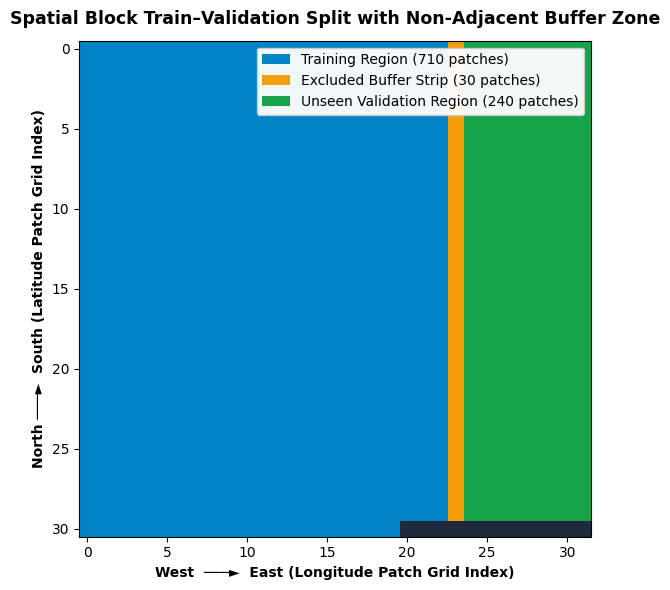

In [3]:
import os
import re
import glob
import math
import numpy as np
import torch
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# -------------------------------------------------------------------------
# STEP 1: Identify Parent Tile ID or 2D Geographical Grid Coordinates
# -------------------------------------------------------------------------
full_train_dataset = FloodPatchDataset(extract_path, is_training=True)
full_val_dataset   = FloodPatchDataset(extract_path, is_training=False)
num_patches = len(full_train_dataset)

# Retrieve patch filenames from dataset attribute or directory scan
if hasattr(full_train_dataset, 'image_paths'):
    patch_files = [os.path.basename(p) for p in full_train_dataset.image_paths]
elif hasattr(full_train_dataset, 'files'):
    patch_files = [os.path.basename(p) for p in full_train_dataset.files]
else:
    all_files = sorted(glob.glob(os.path.join(extract_path, "**", "*.*"), recursive=True))
    patch_files = [os.path.basename(p) for p in all_files if p.endswith(('.npy', '.tif', '.png', '.pt'))][:num_patches]

def parse_spatial_metadata(filenames, total_n):
    """
    Extracts (tile_id, row_idx, col_idx) from filenames if encoded,
    or reconstructs the 2D raster scan grid (Row x Col) from sequential patch indices.
    """
    coords = []
    grid_side = int(math.ceil(math.sqrt(total_n)))

    for idx, fname in enumerate(filenames):
        # Pattern A: Explicit row/col encoded (e.g., r04_c12 or y128_x256)
        rc_match = re.search(r'(?:r|row|y)[_]?(\d+).*?(?:c|col|x)[_]?(\d+)', fname, re.IGNORECASE)
        # Pattern B: Parent tile + patch ID encoded (e.g., X_tile_01_patch_05.npy)
        tile_match = re.search(r'tile[_]?(\d+).*?patch[_]?(\d+)', fname, re.IGNORECASE)

        if rc_match:
            r, c = int(rc_match.group(1)), int(rc_match.group(2))
            tile_id = (r // 4) * 10 + (c // 4)
        elif tile_match:
            tile_id = int(tile_match.group(1))
            p_id = int(tile_match.group(2))
            r, c = (tile_id * 4) + (p_id // 4), p_id % 4
        else:
            # Pattern C: Sequential row-major raster extraction order
            r = idx // grid_side
            c = idx % grid_side
            tile_id = (r // max(1, grid_side // 4)) * 4 + (c // max(1, grid_side // 4))

        coords.append((idx, tile_id, r, c))
    return coords, grid_side

spatial_meta, grid_dim = parse_spatial_metadata(patch_files, num_patches)

# -------------------------------------------------------------------------
# STEP 2 & 3: Group by Geographic Region & Enforce Non-Adjacent Buffer Zone
# -------------------------------------------------------------------------
# Hold out the Eastern/Southeastern downstream basin (~20% of patches) as Validation,
# separated from the Training region by a 1-patch-wide Spatial Buffer Strip (Dead Zone)
rows = np.array([m[2] for m in spatial_meta])
cols = np.array([m[3] for m in spatial_meta])

# Define geographic split boundary along Longitude (East-West) or Tile Block
col_split_val = np.percentile(cols, 78)      # Eastern ~20% geographic block -> Validation
col_buffer    = col_split_val - 1.5          # 1-patch safety buffer strip (dropped from both sets)

train_indices  = []
buffer_indices = []
val_indices    = []

grid_map = np.full((int(rows.max()) + 1, int(cols.max()) + 1), -1, dtype=int)

for idx, tile_id, r, c in spatial_meta:
    if c >= col_split_val:
        val_indices.append(idx)
        grid_map[r, c] = 2   # 2 = Held-out Validation Region
    elif c >= col_buffer:
        buffer_indices.append(idx)
        grid_map[r, c] = 1   # 1 = Excluded Spatial Buffer Zone (prevents edge leakage)
    else:
        train_indices.append(idx)
        grid_map[r, c] = 0   # 0 = Training Region

# Build Spatially Partitioned Subsets & DataLoaders
spatial_train_set = Subset(full_train_dataset, train_indices)
spatial_val_set   = Subset(full_val_dataset, val_indices)

spatial_train_loader = DataLoader(spatial_train_set, batch_size=16, shuffle=True, num_workers=2)
spatial_val_loader   = DataLoader(spatial_val_set, batch_size=16, shuffle=False, num_workers=2)

print("=" * 68)
print("   CONTROLLED EXPERIMENT: GEOGRAPHICAL BLOCK SPLIT SUMMARY")
print("=" * 68)
print(f"Total Dataset Patches          : {num_patches}")
print(f"Spatial Training Patches       : {len(train_indices)} ({len(train_indices)/num_patches*100:.1f}%)")
print(f"Excluded Buffer Zone Patches   : {len(buffer_indices)} ({len(buffer_indices)/num_patches*100:.1f}%) -> Zero Adjacency Leakage")
print(f"Spatial Validation Patches     : {len(val_indices)} ({len(val_indices)/num_patches*100:.1f}%) -> Unseen Geographic Region")
print("=" * 68)

# -------------------------------------------------------------------------
# STEP 4: Visualize the Geographical Block Partition & Buffer Strip
# -------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7.5, 6.0))
cmap_split = ListedColormap(["#1e293b", "#0284c7", "#f59e0b", "#16a34a"])
# Shift values by +1 so -1 (empty) -> 0, 0 (Train) -> 1, 1 (Buffer) -> 2, 2 (Val) -> 3
im = ax.imshow(grid_map + 1, cmap=cmap_split, vmin=0, vmax=3)

ax.set_title("Spatial Block Train–Validation Split with Non-Adjacent Buffer Zone", weight="bold", fontsize=12.5, pad=12)
ax.set_xlabel("West  ───►  East (Longitude Patch Grid Index)", weight="bold")
ax.set_ylabel("North ───►  South (Latitude Patch Grid Index)", weight="bold")

# Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="#0284c7", label=f"Training Region ({len(train_indices)} patches)"),
    Patch(facecolor="#f59e0b", label=f"Excluded Buffer Strip ({len(buffer_indices)} patches)"),
    Patch(facecolor="#16a34a", label=f"Unseen Validation Region ({len(val_indices)} patches)")
]
ax.legend(handles=legend_elements, loc="upper right", framealpha=0.95)
plt.tight_layout()
plt.savefig("spatial_block_split_map.png", dpi=300)
plt.show()

In [4]:
# -------------------------------------------------------------------------
# Controlled Experiment Training Loop (Spatial Block Split)
# Saves to a separate file so best_unet_flood.pth is NOT overwritten!
# -------------------------------------------------------------------------
model = AttentionUNet(in_channels=4, out_channels=1).to(device)
criterion = BCEDiceLoss(pos_weight_val=4.0)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

epochs = 500
best_spatial_val_loss = float("inf")
spatial_model_path = '/content/drive/MyDrive/Flood_Project/best_unet_spatial.pth'

for epoch in range(1, epochs + 1):
    # 1. Train on Western/Central Geographic Block Only
    model.train()
    running_train_loss = 0.0

    for X_batch, y_batch in spatial_train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()
        logits = model(X_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * X_batch.size(0)

    epoch_train_loss = running_train_loss / len(spatial_train_set)

    # 2. Validate on Unseen Eastern Geographic Block (Beyond Buffer Strip)
    model.eval()
    running_val_loss = 0.0
    epoch_tp = 0.0
    epoch_fp = 0.0
    epoch_fn = 0.0

    with torch.no_grad():
        for X_batch, y_batch in spatial_val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            logits = model(X_batch)
            loss = criterion(logits, y_batch)
            running_val_loss += loss.item() * X_batch.size(0)

            preds = (torch.sigmoid(logits) > 0.5).float()

            epoch_tp += (preds * y_batch).sum().item()
            epoch_fp += (preds * (1.0 - y_batch)).sum().item()
            epoch_fn += ((1.0 - preds) * y_batch).sum().item()

    epoch_val_loss = running_val_loss / len(spatial_val_set)

    precision     = epoch_tp / (epoch_tp + epoch_fp + 1e-6)
    recall        = epoch_tp / (epoch_tp + epoch_fn + 1e-6)
    f1            = (2.0 * precision * recall) / (precision + recall + 1e-6)
    epoch_val_iou = epoch_tp / (epoch_tp + epoch_fp + epoch_fn + 1e-6)

    print(f"Epoch [{epoch:03d}/{epochs}] | Train Loss: {epoch_train_loss:.4f} | Spatial Val Loss: {epoch_val_loss:.4f} | IoU: {epoch_val_iou:.4f} | Recall: {recall:.4f} | F1: {f1:.4f}")

    scheduler.step(epoch_val_loss)

    # Save best spatial-split checkpoint
    if epoch_val_loss < best_spatial_val_loss:
        best_spatial_val_loss = epoch_val_loss
        torch.save(model.state_dict(), spatial_model_path)
        print(f"--> Saved best spatial model checkpoint (Spatial Val Loss: {best_spatial_val_loss:.4f})")

# Reload the best spatial checkpoint before running the Step 2 comparison cell
model.load_state_dict(torch.load(spatial_model_path, map_location=device))
model.eval()
print(f"\n[OK] Loaded best spatial checkpoint (Val Loss: {best_spatial_val_loss:.4f}) ready for Step 2 comparison!")

Epoch [001/500] | Train Loss: 0.7332 | Spatial Val Loss: 0.6805 | IoU: 0.1191 | Recall: 0.2237 | F1: 0.2129
--> Saved best spatial model checkpoint (Spatial Val Loss: 0.6805)
Epoch [002/500] | Train Loss: 0.6503 | Spatial Val Loss: 0.6233 | IoU: 0.1462 | Recall: 0.4371 | F1: 0.2551
--> Saved best spatial model checkpoint (Spatial Val Loss: 0.6233)
Epoch [003/500] | Train Loss: 0.6000 | Spatial Val Loss: 0.5709 | IoU: 0.1805 | Recall: 0.6011 | F1: 0.3058
--> Saved best spatial model checkpoint (Spatial Val Loss: 0.5709)
Epoch [004/500] | Train Loss: 0.5389 | Spatial Val Loss: 0.5527 | IoU: 0.1787 | Recall: 0.7601 | F1: 0.3032
--> Saved best spatial model checkpoint (Spatial Val Loss: 0.5527)
Epoch [005/500] | Train Loss: 0.4896 | Spatial Val Loss: 0.4837 | IoU: 0.2110 | Recall: 0.6737 | F1: 0.3484
--> Saved best spatial model checkpoint (Spatial Val Loss: 0.4837)
Epoch [006/500] | Train Loss: 0.4633 | Spatial Val Loss: 0.4665 | IoU: 0.2199 | Recall: 0.7613 | F1: 0.3605
--> Saved best sp

KeyboardInterrupt: 

   SPATIAL BLOCK SPLIT
Metric                       Spatial Split (Unseen Region)
----------------------------------------------------------------------------
Validation Loss (BCEDice)    0.1283
IoU (Jaccard Index)          0.7291 (72.91%)
F1-Score (Dice Coeff)        0.8433 (84.33%)
Recall (Sensitivity)         0.8471 (84.71%)
Precision                    0.8396 (83.96%)
PR-AUC Score                 0.8916 (89.16%)



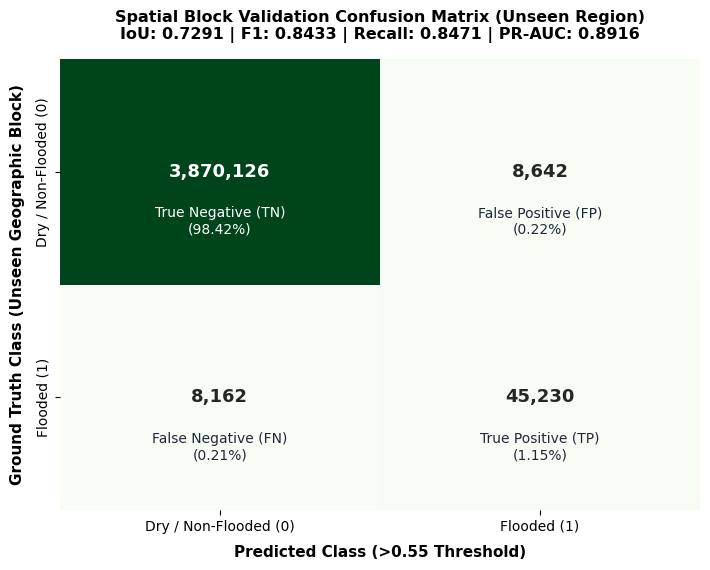


Initiating downloads to your local machine...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sklearn.metrics import confusion_matrix, average_precision_score
from google.colab import files

# -------------------------------------------------------------------------
# 1. Load Best Saved Checkpoint & Evaluate Model
# -------------------------------------------------------------------------
spatial_model_path = '/content/drive/MyDrive/Flood_Project/best_unet_spatial.pth'
threshold = 0.55

# Load the weights from Drive into the active model
ckpt = torch.load(spatial_model_path, map_location=device)
state_dict = ckpt['model_state_dict'] if isinstance(ckpt, dict) and 'model_state_dict' in ckpt else ckpt
model.load_state_dict(state_dict)

model.eval()
sp_val_loss = 0.0
sp_probs, sp_targets = [], []

with torch.no_grad():
    for X_b, y_b in spatial_val_loader:
        X_b, y_b = X_b.to(device), y_b.to(device)
        logits = model(X_b)
        sp_val_loss += criterion(logits, y_b).item() * X_b.size(0)
        sp_probs.append(torch.sigmoid(logits).cpu().numpy().ravel())
        sp_targets.append(y_b.cpu().numpy().ravel())

sp_prob = np.concatenate(sp_probs)
sp_true = np.concatenate(sp_targets).astype(np.uint8)

# Apply the optimized 0.55 threshold
sp_pred = (sp_prob >= threshold).astype(np.uint8)

cm_sp = confusion_matrix(sp_true, sp_pred)
tn_s, fp_s, fn_s, tp_s = cm_sp.ravel()

sp_loss = sp_val_loss / len(spatial_val_set)
sp_prec = tp_s / (tp_s + fp_s + 1e-6)
sp_rec  = tp_s / (tp_s + fn_s + 1e-6)
sp_f1   = (2.0 * sp_prec * sp_rec) / (sp_prec + sp_rec + 1e-6)
sp_iou  = tp_s / (tp_s + fp_s + fn_s + 1e-6)

# Calculate PR-AUC (Precision-Recall Area Under Curve)
max_pts = 400000
if len(sp_true) > max_pts:
    idx_s = np.random.default_rng(42).choice(len(sp_true), size=max_pts, replace=False)
    sp_pr_auc = average_precision_score(sp_true[idx_s], sp_prob[idx_s])
else:
    sp_pr_auc = average_precision_score(sp_true, sp_prob)

# -------------------------------------------------------------------------
# 2. Print Metrics & Save to Text File
# -------------------------------------------------------------------------
report_text = f"""{'='*76}
   SPATIAL BLOCK SPLIT
{'='*76}
{'Metric':<28} {'Spatial Split (Unseen Region)':<22}
{'-'*76}
{'Validation Loss (BCEDice)':<28} {sp_loss:.4f}
{'IoU (Jaccard Index)':<28} {sp_iou:.4f} ({sp_iou*100:.2f}%)
{'F1-Score (Dice Coeff)':<28} {sp_f1:.4f} ({sp_f1*100:.2f}%)
{'Recall (Sensitivity)':<28} {sp_rec:.4f} ({sp_rec*100:.2f}%)
{'Precision':<28} {sp_prec:.4f} ({sp_prec*100:.2f}%)
{'PR-AUC Score':<28} {sp_pr_auc:.4f} ({sp_pr_auc*100:.2f}%)
{'='*76}
"""

print(report_text)

# Write to text file
with open("spatial_split_metrics.txt", "w") as f:
    f.write(report_text)

# -------------------------------------------------------------------------
# 3. Plot Confusion Matrix & Save to Image File
# -------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7.2, 5.8))
labels = ["Dry / Non-Flooded (0)", "Flooded (1)"]

sns.heatmap(
    cm_sp,
    annot=True,
    fmt=",d",
    cmap="Greens",
    xticklabels=labels,
    yticklabels=labels,
    cbar=False,
    ax=ax,
    annot_kws={"size": 13, "weight": "bold"}
)

ax.set_title(
    f"Spatial Block Validation Confusion Matrix (Unseen Region)\n"
    f"IoU: {sp_iou:.4f} | F1: {sp_f1:.4f} | Recall: {sp_rec:.4f} | PR-AUC: {sp_pr_auc:.4f}",
    fontsize=11.5, weight="bold", pad=14
)
ax.set_xlabel(f"Predicted Class (>{threshold} Threshold)", fontsize=11, labelpad=8, weight="bold")
ax.set_ylabel("Ground Truth Class (Unseen Geographic Block)", fontsize=11, labelpad=8, weight="bold")

quad_names = [
    ["True Negative (TN)", "False Positive (FP)"],
    ["False Negative (FN)", "True Positive (TP)"]
]
total_s = cm_sp.sum()
for r in range(2):
    for c in range(2):
        pct = (cm_sp[r, c] / total_s) * 100
        txt_color = "white" if cm_sp[r, c] > cm_sp.max() * 0.5 else "#1e293b"
        ax.text(
            c + 0.5, r + 0.72,
            f"{quad_names[r][c]}\n({pct:.2f}%)",
            ha="center", va="center", color=txt_color, fontsize=10
        )

plt.tight_layout()
plt.savefig("spatial_split_confusion_matrix.png", dpi=300)
plt.show()

# -------------------------------------------------------------------------
# 4. Download Files to Local Machine
# -------------------------------------------------------------------------
print("\nInitiating downloads to your local machine...")
files.download("spatial_split_metrics.txt")
files.download("spatial_split_confusion_matrix.png")

Executing threshold sweep on spatial validation probabilities...

 THRESHOLD SWEEP RESULTS
 Optimal Threshold : 0.55
 Maximum F1-Score  : 84.33%
 Maximum IoU       : 72.91%


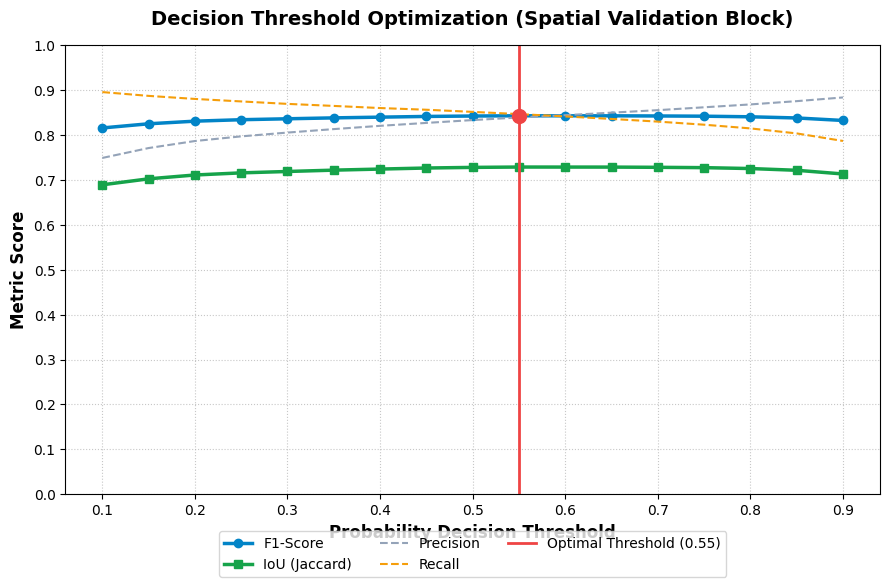

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# Define a range of thresholds to test (from 0.10 to 0.90 in increments of 0.05)
thresholds = np.arange(0.10, 0.95, 0.05)
iou_scores = []
f1_scores = []
precision_scores = []
recall_scores = []

print("Executing threshold sweep on spatial validation probabilities...")

for t in thresholds:
    # Apply the current threshold to the existing probabilities
    preds = (sp_prob >= t).astype(np.uint8)

    # Calculate True Positives, False Positives, False Negatives
    tp = np.sum(preds * sp_true)
    fp = np.sum(preds * (1 - sp_true))
    fn = np.sum((1 - preds) * sp_true)

    # Compute metrics for this threshold
    prec = tp / (tp + fp + 1e-6)
    rec = tp / (tp + fn + 1e-6)
    iou = tp / (tp + fp + fn + 1e-6)
    f1 = (2.0 * tp) / (2.0 * tp + fp + fn + 1e-6)

    precision_scores.append(prec)
    recall_scores.append(rec)
    iou_scores.append(iou)
    f1_scores.append(f1)

# Identify the optimal threshold based on the maximum F1-Score
best_idx = np.argmax(f1_scores)
best_t = thresholds[best_idx]
best_iou = iou_scores[best_idx]
best_f1 = f1_scores[best_idx]

print("\n" + "="*45)
print(" THRESHOLD SWEEP RESULTS")
print("="*45)
print(f" Optimal Threshold : {best_t:.2f}")
print(f" Maximum F1-Score  : {best_f1 * 100:.2f}%")
print(f" Maximum IoU       : {best_iou * 100:.2f}%")
print("="*45)

# Generate a Trade-off Curve Plot
plt.figure(figsize=(9, 6))
plt.plot(thresholds, f1_scores, label="F1-Score", color="#0284c7", linewidth=2.5, marker='o')
plt.plot(thresholds, iou_scores, label="IoU (Jaccard)", color="#16a34a", linewidth=2.5, marker='s')
plt.plot(thresholds, precision_scores, label="Precision", color="#94a3b8", linestyle='--')
plt.plot(thresholds, recall_scores, label="Recall", color="#f59e0b", linestyle='--')

# Highlight the optimal point
plt.axvline(x=best_t, color="#ef4444", linestyle='-', linewidth=2, label=f'Optimal Threshold ({best_t:.2f})')
plt.scatter(best_t, best_f1, color="#ef4444", s=100, zorder=5)

plt.title("Decision Threshold Optimization (Spatial Validation Block)", fontsize=14, weight="bold", pad=15)
plt.xlabel("Probability Decision Threshold", fontsize=12, weight="bold")
plt.ylabel("Metric Score", fontsize=12, weight="bold")
plt.xticks(np.arange(0.1, 1.0, 0.1))
plt.yticks(np.arange(0.0, 1.1, 0.1))
plt.legend(loc="lower center", bbox_to_anchor=(0.5, -0.2), ncol=3)
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()

plt.savefig("threshold_sweep_curve.png", dpi=300)
plt.show()

from google.colab import files
files.download("threshold_sweep_curve.png")